# Qiskit Fall Fest 2026 — Challenge 1: Predict the Output
**IBM Quantum · Vishnu Institute of Technology, Bhimavaram**

**Goal:** Predict the measurement outcome of three single-qubit circuits, run each for 100 shots, and compare the results with the predictions.

| Circuit | Gates applied to \|0⟩ |
|---|---|
| A | X, then measure |
| B | X, X, then measure |
| C | H, then measure |

## 1. Setup

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

import matplotlib.pyplot as plt

SHOTS = 100
sim = AerSimulator()

## 2. Predictions (before running)

- **Circuit A (X):** X is the quantum NOT gate, so it flips |0⟩ to |1⟩. Prediction: **always `1`** (100 / 100).
- **Circuit B (X, X):** The second X flips the qubit back, so X·X = I. Prediction: **always `0`** (100 / 100).
- **Circuit C (H):** H creates the superposition (|0⟩ + |1⟩)/√2, giving 50 % probability for each outcome. Prediction: **about 50 `0`s and 50 `1`s**, with random fluctuation.

**Will Circuit C always give the same result?** No. Each shot is a random outcome, so the counts will differ from run to run (only the probabilities are fixed at 50/50).

## 3. Build the three circuits
Each circuit uses exactly 1 qubit (starting in |0⟩) and 1 classical bit for measurement.

In [2]:
# Circuit A: X gate
qc_a = QuantumCircuit(1, 1, name="Circuit A")
qc_a.x(0)
qc_a.measure(0, 0)

# Circuit B: two X gates
qc_b = QuantumCircuit(1, 1, name="Circuit B")
qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)

# Circuit C: H gate
qc_c = QuantumCircuit(1, 1, name="Circuit C")
qc_c.h(0)
qc_c.measure(0, 0)

for name, qc in [("A", qc_a), ("B", qc_b), ("C", qc_c)]:
    print(f"Circuit {name}")
    print(qc.draw("text"))
    print()

Circuit A
     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 

Circuit B
     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 

Circuit C
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 



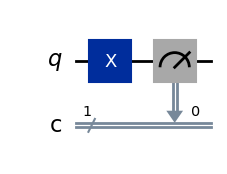

In [3]:
qc_a.draw("mpl")

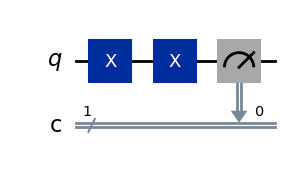

In [4]:
qc_b.draw("mpl")

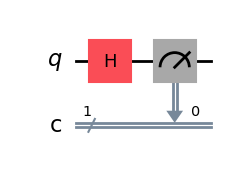

In [5]:
qc_c.draw("mpl")

## 4. Execute each circuit for 100 shots

In [6]:
def run(qc, shots=SHOTS):
    compiled = transpile(qc, sim)
    return sim.run(compiled, shots=shots).result().get_counts()

counts_a = run(qc_a)
counts_b = run(qc_b)
counts_c = run(qc_c)

print("Circuit A (X)    :", counts_a)
print("Circuit B (X, X) :", counts_b)
print("Circuit C (H)    :", counts_c)

Circuit A (X)    : {'1': 100}
Circuit B (X, X) : {'0': 100}
Circuit C (H)    : {'1': 55, '0': 45}


## 5. Histograms

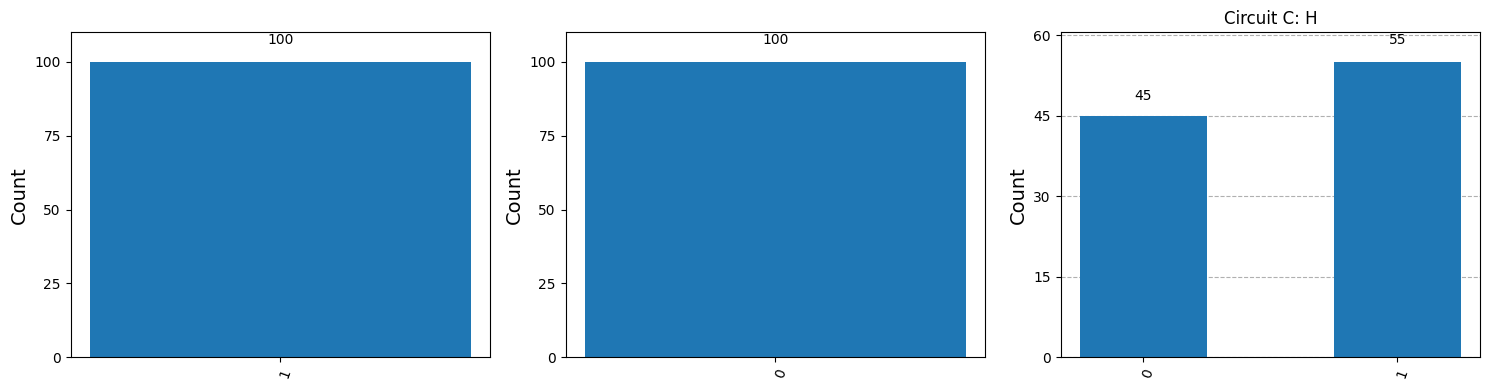

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, counts, title in zip(
    axes,
    [counts_a, counts_b, counts_c],
    ["Circuit A: X", "Circuit B: X, X", "Circuit C: H"],
):
    plot_histogram(counts, ax=ax, title=title)
plt.tight_layout()
plt.show()

## 6. Prediction vs. actual results

In [8]:
predictions = {
    "A": "100 x '1'",
    "B": "100 x '0'",
    "C": "~50 '0' / ~50 '1'",
}
actual = {"A": counts_a, "B": counts_b, "C": counts_c}

print(f"{'Circuit':<8}{'Prediction':<22}{'Actual (100 shots)'}")
print("-" * 60)
for k in "ABC":
    print(f"{k:<8}{predictions[k]:<22}{dict(sorted(actual[k].items()))}")

Circuit Prediction            Actual (100 shots)
------------------------------------------------------------
A       100 x '1'             {'1': 100}
B       100 x '0'             {'0': 100}
C       ~50 '0' / ~50 '1'     {'0': 45, '1': 55}


## 7. Comparison and conclusion

- **Circuit A:** matched the prediction. One X gate flips |0⟩ to |1⟩, so every shot measured `1`.
- **Circuit B:** matched the prediction. Two X gates cancel out, so the qubit returns to |0⟩ and every shot measured `0`.
- **Circuit C:** matched the prediction. The H gate put the qubit in an equal superposition, so the results were split roughly evenly between `0` and `1`. The counts are not exactly 50/50 because quantum measurement is probabilistic, and with only 100 shots, random variation is expected. Re-running the cell gives slightly different counts, so Circuit C does **not** always produce the same result.

**Key takeaways:** X and X·X behave deterministically (they give a fixed outcome), while H produces randomness through superposition. More shots would bring Circuit C closer to a 50/50 split.